In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



from caldis.core.system import System
from caldis.fluids import CoolPropBackend

from caldis.components import FluidBoundary
from caldis.components import Compressor

#SizingHX = recuperator
# SimpleHeater = inter /after-cooler

from caldis.components import SizingHX, SimpleHeater

#FlashTank
from caldis.components import FlashTank , Mixer , Valve

#only for L3
from caldis.components import Splitter
from caldis.solvers import solve        

from CoolProp.CoolProp import PropsSI

### Paramètres

In [3]:

gas = "Methane"
be_methane = CoolPropBackend(gas)
T0 = 273.15 + 25.0  # K

T_IC = T0 + 5.0 # K
T_aftercooler = T0 + 5.0 # K


P_high = 100e5

comp_is_e = 0.75 
HX_pinch = 5 # K
HP_recup_coeff = 1000 # W/m2K
LP_recup_coeff = 500 # W/m2K

mdot_liq = 1 # kg/s

# L0 : Baseline cycle

In [4]:
source    = FluidBoundary("source", T=T0, backend=be_methane, p=1e5)

Mixer_ = Mixer("Mixer", backend=be_methane)
# Compressors (4 compressors in series, with intercooling between each stage)

Comp1 = Compressor("Comp1", eta_is=comp_is_e, backend=be_methane)
Comp2 = Compressor("Comp2", eta_is=comp_is_e, backend=be_methane)
Comp3 = Compressor("Comp3", eta_is=comp_is_e, backend=be_methane)
Comp4 = Compressor("Comp4", eta_is=comp_is_e, backend=be_methane)

IC1 = SimpleHeater("IC1", backend=be_methane)
IC2 = SimpleHeater("IC2",backend=be_methane)
IC3 = SimpleHeater("IC3",backend=be_methane)

Aftercooler = SimpleHeater("Aftercooler", T_source=T_aftercooler, backend=be_methane)

Recuperator = SizingHX("Recuperator", h_hot = HP_recup_coeff, h_cold = LP_recup_coeff, backend_hot=be_methane, backend_cold=be_methane, area_ratio_cold_to_hot=1.0)

#Valve     def __init__(self, name, Kv=None, backend=None, flow_law="quadratic", eps=1e-9):
valve = Valve("valve", backend=be_methane)

Flash = FlashTank("Flash", backend=be_methane)

liquid_product = FluidBoundary("liquid_product", backend=be_methane)


In [5]:
sys = System("cycle")

sys.add( source, Comp1, IC1, Comp2, IC2, Comp3, IC3, Comp4, Aftercooler, Recuperator, valve, Flash, Mixer_, liquid_product)

sys.connect(source.port, Mixer_.in1)
#afficher les attributs de Comp1
#print(Comp1.attributes#)

sys.connect(Mixer_.out, Comp1.inl)
sys.connect(Comp1.out, IC1.inl)
sys.connect(IC1.out, Comp2.inl)
sys.connect(Comp2.out, IC2.inl)
sys.connect(IC2.out, Comp3.inl)
sys.connect(Comp3.out, IC3.inl)
sys.connect(IC3.out, Comp4.inl)

#after cooler
sys.connect(Comp4.out, Aftercooler.inl)
sys.connect(Aftercooler.out, Recuperator.hot_in)


#Recuperator
sys.connect(Recuperator.hot_out, valve.inl)
sys.connect(valve.out, Flash.inl)

sys.connect(Recuperator.cold_in, Flash.vap)
sys.connect(Recuperator.cold_out, Mixer_.in2)

sys.connect(Flash.liq, liquid_product.port)

# add constraints on the compressors, r=3.16 for all stages
sys.add_constraint(lambda: Comp1.out.p - 3.16 * Comp1.inl.p, "fn=comp1_pressure_ratio")
sys.add_constraint(lambda: Comp2.out.p - 3.16 * Comp2.inl.p, "fn=comp2_pressure_ratio")
sys.add_constraint(lambda: Comp3.out.p - 3.16 * Comp3.inl.p, "fn=comp3_pressure_ratio")
sys.add_constraint(lambda: Comp4.out.p - 3.16 * Comp4.inl.p, "fn=comp4_pressure_ratio")

#refroidisseurs sortent à T0 + 5K:
sys.add_constraint(lambda hx=IC1: hx.out.T - T_IC, "fn=IC1_T_out")
sys.add_constraint(lambda hx=IC2: hx.out.T - T_IC, "fn=IC2_T_out")
sys.add_constraint(lambda hx=IC3: hx.out.T - T_IC, "fn=IC3_T_out")



sys.add_constraint(lambda: Aftercooler.out.T - T_aftercooler, "fn=aftercooler_temperature")


sys.add_constraint(lambda: liquid_product.port.mdot - mdot_liq, "fn=liquid_product_mass_flow")

sys.add_constraint(lambda: Recuperator.hot_in.T - Recuperator.cold_out.T - HX_pinch, "fn=recuperator_pinch")


# ne pas mettre cette contrainte sys.add_constraint(lambda: valve.out.p - 1e5, "fn=valve_outlet_pressure")

sol = solve(sys)



✓ DOF: square (97 unknowns)
✓ start point: evaluable
⚠ 10 start-sanity warning(s):
   - Comp1: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp2: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp3: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp4: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Recuperator: temperature cross at start (dT1=0.0, dT2=0.0 K)
   - Recuperator: hot inlet/outlet nearly equal -> LMTD/flow degenerate
   - Recuperator: cold inlet/outlet nearly equal -> cold MASS FLOW is undetermined (anchor the cold-side inlet/outlet TEMPERATURES)
   - Flash: vap mdot should be < 0 (outlet)
   - Flash: liq mdot should be < 0 (outlet)
   - Mixer: out mdot should be < 0 (outlet)
  (non-blocking.)
  direct Newton: failed -> fallback to homotopy (1 it, |F_scaled|=1.6e+01)
✗ FAILED: homotopy stuck at lambda=0.0000 (dlam<0.001): jacobienne singulière (it 1)

=== convergence report (FAILED) ===
message: homotop

### Now that the systeme is squared, let's impose realistic initial vales.

In [6]:
from caldis.solvers.autostart import autostart

pk = [1e5 * 3.16**k for k in range(5)]          # 1 ; 3,16 ; 9,99 ; 31,6 ; 99,7 bar
T_comp_out = [411.6, 417.9, 418.6, 420.4]       # K
comps, coolers = [Comp1, Comp2, Comp3, Comp4], [IC1, IC2, IC3, Aftercooler]

for k, (C, X) in enumerate(zip(comps, coolers)):
    sys.set_start_port(C.inl,  p=pk[k],   T=T0 if k == 0 else T_IC)
    sys.set_start_port(C.out,  p=pk[k+1], T=T_comp_out[k])
    sys.set_start_port(X.inl,  p=pk[k+1], T=T_comp_out[k])
    sys.set_start_port(X.out,  p=pk[k+1], T=T_IC)

for prt in (source.port, Mixer_.in1, Mixer_.in2, Mixer_.out):
    sys.set_start_port(prt, p=1e5, T=T0)

sys.set_start_port(Recuperator.hot_in,   p=pk[4], T=T_IC)
sys.set_start_port(Recuperator.hot_out,  p=pk[4], T=217.0)
sys.set_start_port(valve.inl,            p=pk[4], T=217.0)
sys.set_start_port(Recuperator.cold_in,  p=1e5,   T=113.0)  # vapeur sat., légèrement surchauffée
sys.set_start_port(Flash.vap,            p=1e5,   T=113.0)
sys.set_start_port(Recuperator.cold_out, p=1e5,   T=T0)
sys.set_start_port(Flash.liq,            p=1e5,   T=110.0)  # liquide sat., légèrement sous-refroidi

autostart(sys)
sol = solve(sys, verbose=True)

✓ DOF: square (97 unknowns)
✓ start point: evaluable
⚠ 3 start-sanity warning(s):
   - Flash: vap mdot should be < 0 (outlet)
   - Flash: liq mdot should be < 0 (outlet)
   - Mixer: out mdot should be < 0 (outlet)
  (non-blocking.)
  direct Newton: ok (8 it, |F_scaled|=2.0e-09)
✓ SOLVED (|F_scaled|=2.0e-09)


### MÉTRIQUES DU PARAGRAPHE « Comparison metrics »


In [7]:
# =====================================================================
# MÉTRIQUES DU PARAGRAPHE « Comparison metrics »
# =====================================================================
def w_min(fluid, T0, p_feed=1e5, p_prod=1e5):
    """Travail minimal réversible [J/kg] : T0*(s_feed - s_liq) - (h_feed - h_liq)."""
    s_f, h_f = (PropsSI(k, "T", T0, "P", p_feed, fluid) for k in ("S", "H"))
    s_l, h_l = (PropsSI(k, "Q", 0, "P", p_prod, fluid) for k in ("S", "H"))
    return T0 * (s_f - s_l) - (h_f - h_l)
 
 
def lng_metrics(compressors, liquid_port, circ_port, expanders=(), W_pre=0.0,
                fluid="Methane", T0=298.15):
    """y, w, figure de mérite.  Convention : Wtotal = Wcomp - Wexp + Wpre  (>0 = consommé).
    Wdot < 0 pour un compresseur, > 0 pour une turbine (convention des notebooks)."""
    m_liq, m_circ = abs(liquid_port.mdot), abs(circ_port.mdot)
    W_comp = -sum(c.Wdot for c in compressors)
    W_exp = sum(e.Wdot for e in expanders)
    W_tot = W_comp - W_exp + W_pre
    w = W_tot / m_liq
    wm = w_min(fluid, T0)
    return dict(y=m_liq / m_circ, m_circ=m_circ, W_comp=W_comp, W_exp=W_exp,
                W_tot=W_tot, w=w, w_kWh_per_kg=w / 3.6e6, w_min=wm, fom=wm / w)
 
 
def hx_profile(hx, fluid, n=200):
    """Profil T_chaud / T_froid le long du récupérateur (contre-courant, propriétés réelles).
    Sert à vérifier a posteriori le pincement INTERNE que le modèle mono-zone ne voit pas."""
    hi, ho, ci, co = hx.hot_in, hx.hot_out, hx.cold_in, hx.cold_out
    m_h, m_c = abs(hi.mdot), abs(ci.mdot)
    h_c = np.linspace(ci.h, co.h, n)                    # du bout froid au bout chaud
    h_h = ho.h + (m_c / m_h) * (h_c - ci.h)             # bilan d'énergie local
    T_c = np.array([PropsSI("T", "P", ci.p, "H", h, fluid) for h in h_c])
    print("T_c", T_c)
    T_h = np.array([PropsSI("T", "P", hi.p, "H", h, fluid) for h in h_h])
    print("T_h", T_h)
    return T_h, T_c

def hx_profile_Q(hx, fluid, n=200):
    hi, ho, ci, co = hx.hot_in, hx.hot_out, hx.cold_in, hx.cold_out
    m_h, m_c = abs(hi.mdot), abs(ci.mdot)
    h_c = np.linspace(ci.h, co.h, n)
    Q   = m_c * (h_c - ci.h)                       # [W], depuis le bout froid
    h_h = ho.h + Q / m_h
    T_c  = np.array([PropsSI("T", "P", ci.p, "H", h, fluid) for h in h_c])
    T_h  = np.array([PropsSI("T", "P", hi.p, "H", h, fluid) for h in h_h])
    cp_c = np.array([PropsSI("C", "P", ci.p, "H", h, fluid) for h in h_c])
    cp_h = np.array([PropsSI("C", "P", hi.p, "H", h, fluid) for h in h_h])
    return dict(Q=Q, T_h=T_h, T_c=T_c, mcp_h=m_h * cp_h, mcp_c=m_c * cp_c)
 
def energy_closure(source_port, liquid_port, machines, coolers):
    """1er principe sur tout le cycle (doit être ~0) :
    Q_reçu + W_reçu = m_liq*h_liq - m_source*h_source."""
    Q_in = sum(c.Qdot for c in coolers)
    W_in = -sum(m.Wdot for m in machines)
    out_minus_in = abs(liquid_port.mdot) * liquid_port.h - abs(source_port.mdot) * source_port.h
    return Q_in + W_in - out_minus_in

res = lng_metrics([Comp1, Comp2, Comp3, Comp4], liquid_product.port, Comp1.inl)
T_h, T_c = hx_profile(Recuperator, "Methane")          # pincement interne, vérification a posteriori
res = lng_metrics([Comp1, Comp2, Comp3, Comp4], liquid_product.port, Comp1.inl)
T_h, T_c = hx_profile(Recuperator, "Methane")
dT = T_h - T_c
bilan = energy_closure(source.port, liquid_product.port,
                       [Comp1, Comp2, Comp3, Comp4], [IC1, IC2, IC3, Aftercooler])

print("=" * 52)
print(f"{'RÉSULTATS L0':^52}")
print("=" * 52)
print(f"{'Rendement de liquéfaction y':<34}{100*res['y']:>10.2f} %      (attendu ≈ 9 %)")
print(f"{'Débit circulant':<34}{res['m_circ']:>10.2f} kg/s   (attendu ≈ 11)")
print(f"{'Travail de compression':<34}{res['W_comp']/1e6:>10.2f} MW")
print(f"{'Travail spécifique w':<34}{res['w']/1e3:>10.0f} kJ/kg   (attendu 1.1–1.2e4)")
print(f"{'':<34}{res['w_kWh_per_kg']:>10.2f} kWh/kg")
print(f"{'Travail minimal w_min':<34}{res['w_min']/1e3:>10.0f} kJ/kg   (attendu ≈ 1083)")
print(f"{'Figure de mérite w_min/w':<34}{100*res['fom']:>10.1f} %      (attendu ≈ 9 %)")
print("-" * 52)
print(f"{'ΔT bout chaud (pincement imposé)':<34}{dT[-1]:>10.1f} K")
print(f"{'ΔT bout froid':<34}{dT[0]:>10.1f} K")
print(f"{'ΔT minimum interne':<34}{dT.min():>10.1f} K        ({'OK' if dT.min() >= 5 - 1e-6 else 'PINCEMENT < 5 K !'})")
print(f"{'Fermeture du bilan d’énergie':<34}{bilan:>10.2e} W")
print("=" * 52)

print(f"{'Aire récupérateur A_hot (= A_cold)':<34}{Recuperator.A_hot:>10.0f} m²")
print(f"{'Aire totale (chaud + froid)':<34}{Recuperator.A_total:>10.0f} m²")
print(f"{'UA':<34}{Recuperator.UA/1e3:>10.1f} kW/K")
print(f"{'Puissance échangée Q':<34}{Recuperator.Qdot/1e6:>10.2f} MW")

T_c [111.50762598 112.41439958 113.32354852 114.23490382 115.14831818
 116.06366196 116.98082008 117.89968943 118.82017693 119.74219791
 120.66567483 121.59053627 122.51671611 123.44415283 124.372789
 125.30257078 126.23344762 127.16537185 128.09829851 129.03218504
 129.96699114 130.9026786  131.83921108 132.77655408 133.71467472
 134.65354169 135.59312516 136.53339664 137.47432893 138.41589604
 139.3580731  140.30083633 141.24416295 142.1880311  143.13241985
 144.07730908 145.02267947 145.96851245 146.91479016 147.86149538
 148.80861153 149.7561226  150.70401316 151.65226829 152.60087353
 153.54981492 154.49907892 155.44865239 156.39852258 157.34867709
 158.29910388 159.2497912  160.20072762 161.15190196 162.10330333
 163.05492106 164.00674474 164.95876413 165.91096924 166.86335021
 167.8158974  168.7686013  169.72145257 170.674442   171.62756051
 172.58079913 173.53414903 174.48760144 175.44114772 176.39477929
 177.34848767 178.30226444 179.25610124 180.20998979 181.16392184
 182.117

# L.3 add an splitter

In [8]:
gas = "Methane"
be_methane = CoolPropBackend(gas)
T0 = 273.15 + 25.0  # K

T_IC = T0 + 5.0 # K
T_aftercooler = T0 + 5.0 # K


P_high = 100e5

comp_is_e = 0.75 
HX_pinch = 5 # K
HP_recup_coeff = 1000 # W/m2K
LP_recup_coeff = 500 # W/m2K

mdot_liq = 1 # kg/s

eta_exp    = 0.80
x_expander = 0.01      # fraction vers le détendeur, relue par la contrainte à chaque solve



In [9]:
from caldis.components import Turbine   

source_L3    = FluidBoundary("source", T=T0, backend=be_methane, p=1e5)

Mixer_L3 = Mixer("Mixer", backend=be_methane)
# Compressors (4 compressors in series, with intercooling between each stage)

Comp1_L3 = Compressor("Comp1", eta_is=comp_is_e, backend=be_methane)
Comp2_L3 = Compressor("Comp2", eta_is=comp_is_e, backend=be_methane)
Comp3_L3 = Compressor("Comp3", eta_is=comp_is_e, backend=be_methane)
Comp4_L3 = Compressor("Comp4", eta_is=comp_is_e, backend=be_methane)

IC1_L3 = SimpleHeater("IC1", backend=be_methane)
IC2_L3 = SimpleHeater("IC2",backend=be_methane)
IC3_L3 = SimpleHeater("IC3",backend=be_methane)

Aftercooler_L3 = SimpleHeater("Aftercooler", backend=be_methane)

Recuperator_L3 = SizingHX("Recuperator", h_hot = HP_recup_coeff, h_cold = LP_recup_coeff, backend_hot=be_methane, backend_cold=be_methane, area_ratio_cold_to_hot=1.0)

#Valve     def __init__(self, name, Kv=None, backend=None, flow_law="quadratic", eps=1e-9):

valve_L3 = Valve("valve", backend=be_methane)

Flash_L3 = FlashTank("Flash", backend=be_methane)

liquid_product_L3 = FluidBoundary("liquid_product", backend=be_methane) #methane outlet

Splitter_L3    = Splitter("Splitter", backend=be_methane)
Expander_L3    = Turbine("Expander", eta_is=eta_exp, backend=be_methane)
Mixer_flash_L3 = Mixer("Mixer_flash", backend=be_methane)   # nom différent du mélangeur d'appoint "Mixer"


In [10]:
sys_L3 = System("cycle_L3")
sys_L3.add(source_L3, Mixer_L3, Comp1_L3, IC1_L3, Comp2_L3, IC2_L3, Comp3_L3, IC3_L3, Comp4_L3,
           Aftercooler_L3, Splitter_L3, Expander_L3, Recuperator_L3, valve_L3,
           Mixer_flash_L3, Flash_L3, liquid_product_L3)

sys_L3.connect(source_L3.port, Mixer_L3.in1)
sys_L3.connect(Mixer_L3.out, Comp1_L3.inl)
sys_L3.connect(Comp1_L3.out, IC1_L3.inl)
sys_L3.connect(IC1_L3.out, Comp2_L3.inl)
sys_L3.connect(Comp2_L3.out, IC2_L3.inl)
sys_L3.connect(Comp3_L3.inl, IC2_L3.out)  
sys_L3.connect(Comp3_L3.out, IC3_L3.inl)
sys_L3.connect(IC3_L3.out, Comp4_L3.inl)
sys_L3.connect(Comp4_L3.out, Aftercooler_L3.inl)
sys_L3.connect(Aftercooler_L3.out, Splitter_L3.inl)
sys_L3.connect(Splitter_L3.out1, Recuperator_L3.hot_in)
sys_L3.connect(Splitter_L3.out2, Expander_L3.inl)
sys_L3.connect(Expander_L3.out, Mixer_flash_L3.in1)

sys_L3.connect(Recuperator_L3.hot_out, valve_L3.inl)
sys_L3.connect(valve_L3.out, Mixer_flash_L3.in2)

sys_L3.connect(Mixer_flash_L3.out, Flash_L3.inl)
sys_L3.connect(Recuperator_L3.cold_in, Flash_L3.vap)
sys_L3.connect(Recuperator_L3.cold_out, Mixer_L3.in2)
sys_L3.connect(Flash_L3.liq, liquid_product_L3.port)

#add constraints on the compressors, r=3.16 for all stages
sys_L3.add_constraint(lambda: Comp1_L3.out.p - 3.16 * Comp1_L3.inl.p, "fn=comp1_pressure_ratio")
sys_L3.add_constraint(lambda: Comp2_L3.out.p - 3.16 * Comp2_L3.inl.p, "fn=comp2_pressure_ratio")
sys_L3.add_constraint(lambda: Comp3_L3.out.p - 3.16 * Comp3_L3.inl.p, "fn=comp3_pressure_ratio")
sys_L3.add_constraint(lambda: Comp4_L3.out.p - 3.16 * Comp4_L3.inl.p, "fn=comp4_pressure_ratio")

#refroidisseurs sortent à T0 + 5K:
sys_L3.add_constraint(lambda hx=IC1_L3: hx.out.T - T_IC, "fn=IC1_T_out")
sys_L3.add_constraint(lambda hx=IC2_L3: hx.out.T - T_IC, "fn=IC2_T_out")
sys_L3.add_constraint(lambda hx=IC3_L3: hx.out.T - T_IC, "fn=IC3_T_out")

sys_L3.add_constraint(lambda hx=Aftercooler_L3: hx.out.T - T_aftercooler, "fn=aftercooler_temperature")

#T_source=T_aftercooler

#sys_L3.add_constraint(lambda: Aftercooler_L3.out.T - T_aftercooler, "fn=aftercooler_temperature")


sys_L3.add_constraint(lambda: liquid_product_L3.port.mdot - mdot_liq, "fn=liquid_product_mass_flow")

sys_L3.add_constraint(lambda: Recuperator_L3.hot_in.T - Recuperator_L3.cold_out.T - HX_pinch, "fn=recuperator_pinch")


# les débits de sortie sont négatifs dans la convention des ports : 

sys_L3.add_constraint(lambda: Splitter_L3.out2.mdot + x_expander * Splitter_L3.inl.mdot, "split_expander")

sol_L3 = solve(sys_L3)

✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 15 start-sanity warning(s):
   - Mixer: out mdot should be < 0 (outlet)
   - Comp1: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp2: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp3: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Comp4: p_out (1.00 bar) must be > p_in (1.00 bar) for compression
   - Splitter: out1 mdot should be < 0 (outlet)
   - Splitter: out2 mdot should be < 0 (outlet)
   - Expander: p_out (1.00 bar) must be < p_in (1.00 bar) for expansion
   - Expander: inlet 112 K seems cold for a gas turbine (forgotten hot start?)
   - Recuperator: temperature cross at start (dT1=0.0, dT2=0.0 K)
   - Recuperator: hot inlet/outlet nearly equal -> LMTD/flow degenerate
   - Recuperator: cold inlet/outlet nearly equal -> cold MASS FLOW is undetermined (anchor the cold-side inlet/outlet TEMPERATURES)
   - Mixer_flash: out mdot should be < 0 (outlet)
   - Flash: vap mdot 

In [11]:
if "results" not in globals():          # protège : relancer cette cellule n'efface rien
    results, snapshots = {}, {}         # xe -> métriques ; xe -> {nom_variable: valeur}

def _key(xe):                           # évite 0.1+0.2 != 0.3
    return round(float(xe), 4)

def save_snapshot(xe):
    snapshots[_key(xe)] = {v.name: v.value for v in sys_L3.unknowns}

def solve_xe(xe_list, steps=40, verbose=False):
    """Calcule les xe demandés sans effacer les précédents.
    Repart de la solution déjà calculée la plus proche (jamais de l'état courant)."""
    global x_expander                   # INDISPENSABLE : sinon la lambda de split ne voit pas le changement
    for xe in sorted(map(_key, xe_list)):
        if xe in results:
            print(f"{xe:6.3f}  déjà calculé (results.pop({xe}) pour le refaire)")
            continue
        if not snapshots:
            print("Aucun point de départ : résous xe=0.01, puis save_snapshot(0.01)")
            return
        xe0 = min(snapshots, key=lambda k: abs(k - xe))          # voisin le plus proche
        for v in sys_L3.unknowns:
            v.start = snapshots[xe0][v.name]
        x_expander = xe
        sol = solve(sys_L3, steps=steps, verbose=verbose)
        if not sol.success:
            print(f"{xe:6.3f}  ✗ échec (parti de xe={xe0})")
            continue                                             # on tente les xe suivants
        save_snapshot(xe)

        comps_L3 = [Comp1_L3, Comp2_L3, Comp3_L3, Comp4_L3]
        res = lng_metrics(comps_L3, liquid_product_L3.port, Mixer_L3.out, expanders=[Expander_L3])
        T_h, T_c = hx_profile(Recuperator_L3, "Methane")
        prof = hx_profile_Q(Recuperator_L3, "Methane")      # AVANT le dict

        row = dict(xe=xe, **res,
                   dT_hot=Recuperator_L3.hot_in.T - Recuperator_L3.cold_out.T,
                   dT_cold=Recuperator_L3.hot_out.T - Recuperator_L3.cold_in.T,
                   dT_int=(T_h - T_c).min(),
                   A_hot=Recuperator_L3.A_hot, Q_recup=Recuperator_L3.Qdot,
                   T_exp_out=Expander_L3.out.T,
                   prof=prof,
                   mcp_ratio_warm=prof["mcp_h"][-1] / prof["mcp_c"][-1])
        results[xe] = row
        flag = "  ⚠ pincement violé" if row["dT_int"] < 4.99 else ""
        print(f"{xe:6.3f}  ✓  y={res['y']*100:5.2f} %  w={res['w']/1e3:6.0f} kJ/kg  "
              f"FOM={res['fom']*100:4.1f} %  ΔTint={row['dT_int']:6.2f} K{flag}")

### Let's initiate with realistic values

In [12]:
print(len(sys_L3.unknowns))      # attendu : 121

121


In [13]:
x_expander = 0.01
vals_L0 = {v.name: v.value for v in sys.unknowns}
by_name = {v.name: v for v in sys_L3.unknowns}

# 1) les 97 variables communes avec L0
by_name = {v.name: v for v in sys_L3.unknowns}      # reconstruit APRÈS la vérification ci-dessus

missing = [k for k in vals_L0 if k not in by_name]
print("variables de L0 absentes de L3 :", missing)  # attendu : []

for k, val in vals_L0.items():
    if k in by_name:
        by_name[k].start = val
# 2) les 24 nouvelles (splitter, détendeur, mixer_flash)
xe   = x_expander
m0   = vals_L0["Comp1.inl.mdot"]
p_hi = vals_L0["Aftercooler.out.p"]
h_hi = vals_L0["Aftercooler.out.h"]
h_v  = vals_L0["valve.out.h"]
h_e  = PropsSI("H", "P", 1e5, "T", 120.4, "Methane")
h_mix = (1 - xe) * h_v + xe * h_e

new = {
    "Splitter.inl.p":  p_hi, "Splitter.inl.h":  h_hi, "Splitter.inl.mdot":    m0,
    "Splitter.out1.p": p_hi, "Splitter.out1.h": h_hi, "Splitter.out1.mdot": -(1 - xe) * m0,
    "Splitter.out2.p": p_hi, "Splitter.out2.h": h_hi, "Splitter.out2.mdot": -xe * m0,
    "Expander.inl.p":  p_hi, "Expander.inl.h":  h_hi, "Expander.inl.mdot":   xe * m0,
    "Expander.out.p":  1e5,  "Expander.out.h":  h_e,  "Expander.out.mdot":  -xe * m0,
    "Mixer_flash.in1.p": 1e5, "Mixer_flash.in1.h": h_e,   "Mixer_flash.in1.mdot":  xe * m0,
    "Mixer_flash.in2.p": 1e5, "Mixer_flash.in2.h": h_v,   "Mixer_flash.in2.mdot": (1 - xe) * m0,
    "Mixer_flash.out.p": 1e5, "Mixer_flash.out.h": h_mix, "Mixer_flash.out.mdot": -m0,
}
for k, val in new.items():
    by_name[k].start = val

sol_L3 = solve(sys_L3, verbose=True)
if sol_L3.success:
    save_snapshot(0.01)          # <- le point de départ pour solve_xe
    print("snapshot xe=0.01 sauvegardé")

variables de L0 absentes de L3 : []
✓ DOF: square (121 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Expander: inlet 303 K seems cold for a gas turbine (forgotten hot start?)
  (non-blocking.)
  direct Newton: ok (4 it, |F_scaled|=1.3e-10)
✓ SOLVED (|F_scaled|=1.3e-10)
snapshot xe=0.01 sauvegardé


### Quick check 

In [14]:
Tsat_1bar = 111.67  # K, CH4 à 1 bar (PropsSI("T","P",1e5,"Q",1,"Methane"))
print(f"T sortie détendeur : {Expander_L3.out.T:.1f} K  (surchauffe {Expander_L3.out.T - Tsat_1bar:.1f} K)")
print(f"W détendeur        : {Expander_L3.Wdot/1e3:.1f} kW")
print(f"ΔT bout chaud      : {Recuperator_L3.hot_in.T - Recuperator_L3.cold_out.T:.2f} K  (doit valoir 5)")
print(f"ΔT bout froid      : {Recuperator_L3.hot_out.T - Recuperator_L3.cold_in.T:.2f} K")

T sortie détendeur : 120.4 K  (surchauffe 8.8 K)
W détendeur        : 30.4 kW
ΔT bout chaud      : 5.00 K  (doit valoir 5)
ΔT bout froid      : 105.10 K


## Code fournit adapté

In [15]:
solve_xe([0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6])     # première passe


T_c [111.50762598 112.41439958 113.32354852 114.23490388 115.14831818
 116.06366196 116.98082008 117.89968943 118.82017693 119.74219791
 120.66567483 121.59053627 122.51671611 123.44415283 124.372789
 125.30257078 126.23344762 127.16537185 128.09829851 129.03218504
 129.96699114 130.9026786  131.83921108 132.77655408 133.71467472
 134.65354169 135.59312516 136.53339664 137.47432893 138.41589604
 139.3580731  140.30083633 141.24416295 142.1880311  143.13241985
 144.07730908 145.02267947 145.96851245 146.91479016 147.86149538
 148.80861153 149.7561226  150.70401316 151.65226829 152.60087353
 153.54981492 154.49907892 155.44865239 156.39852258 157.34867709
 158.29910388 159.2497912  160.20072762 161.15190196 162.10330333
 163.05492106 164.00674474 164.95876413 165.91096924 166.86335021
 167.8158974  168.7686013  169.72145257 170.674442   171.62756051
 172.58079913 173.53414903 174.48760144 175.44114772 176.39477929
 177.34848767 178.30226444 179.25610124 180.20998979 181.16392184
 182.117

In [16]:
solve_xe(np.arange(0.40, 0.5001, 0.01))                         # détail, n'efface rien


 0.400  déjà calculé (results.pop(0.4) pour le refaire)
T_c [111.50762598 112.41439958 113.32354852 114.23490388 115.14831818
 116.06366196 116.98082008 117.89968943 118.82017693 119.74219791
 120.66567483 121.59053627 122.51671611 123.44415283 124.372789
 125.30257078 126.23344762 127.16537185 128.09829851 129.03218504
 129.96699114 130.9026786  131.83921108 132.77655408 133.71467472
 134.65354169 135.59312516 136.53339664 137.47432893 138.41589604
 139.3580731  140.30083633 141.24416295 142.1880311  143.13241985
 144.07730908 145.02267947 145.96851245 146.91479016 147.86149538
 148.80861153 149.7561226  150.70401316 151.65226829 152.60087353
 153.54981492 154.49907892 155.44865239 156.39852258 157.34867709
 158.29910388 159.2497912  160.20072762 161.15190196 162.10330333
 163.05492106 164.00674474 164.95876413 165.91096924 166.86335021
 167.8158974  168.7686013  169.72145257 170.674442   171.62756051
 172.58079913 173.53414903 174.48760144 175.44114772 176.39477929
 177.34848767 178.

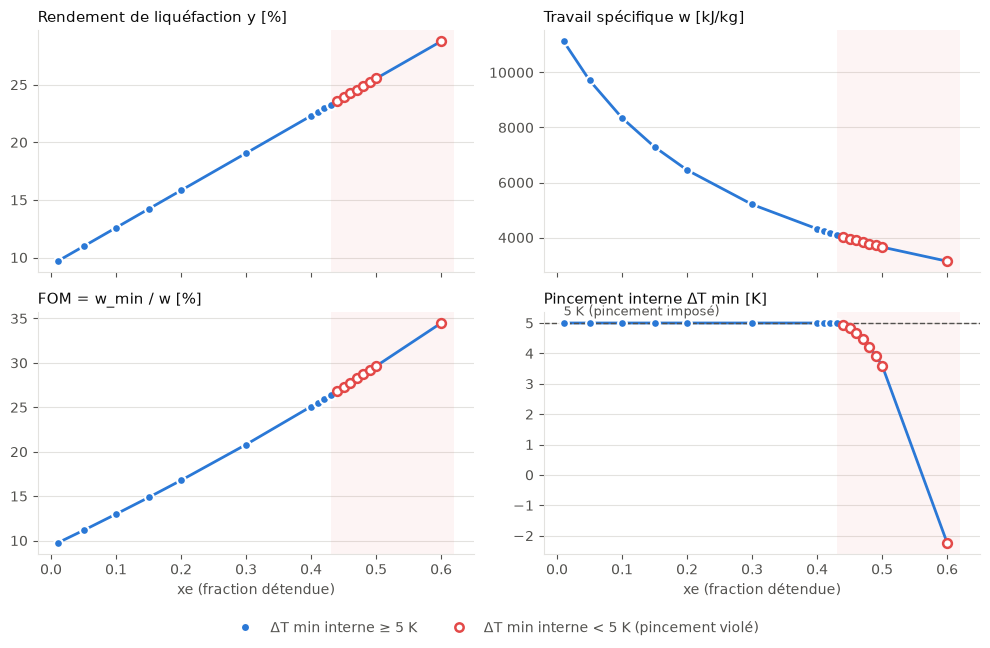

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── 1) DataFrame lisible (sans .style) ───────────────────────────────────────
df = pd.DataFrame(results.values()).sort_values("xe").set_index("xe")   # au lieu de pd.DataFrame(results).drop_duplicates(...)

out = pd.DataFrame({
    "y [%]":           df["y"] * 100,
    "ṁ_circ [kg/s]":   df["m_circ"],
    "W_comp [MW]":     df["W_comp"] / 1e6,
    "W_exp [MW]":      df["W_exp"] / 1e6,
    "W_tot [MW]":      df["W_tot"] / 1e6,
    "w [kJ/kg]":       df["w"] / 1e3,
    "w [kWh/kg]":      df["w_kWh_per_kg"],
    "FOM [%]":         df["fom"] * 100,
    "ΔT min int. [K]": df["dT_int"],
})
if "A_hot" in df:
    out["A_hot [m²]"] = df["A_hot"]

out = out.round(2).round({"w [kJ/kg]": 0, "A_hot [m²]": 0})
out        # affichage du DataFrame, plus de notation scientifique

# ── 2) Graphique : une métrique par panneau ──────────────────────────────────
INK, MUTED, GRID, BLUE, RED = "#0b0b0b", "#52514e", "#e3e2df", "#2a78d6", "#e34948"

ok = out["ΔT min int. [K]"] >= 4.99               # pincement interne respecté ?
panels = [("y [%]",           "Rendement de liquéfaction y [%]"),
          ("w [kJ/kg]",       "Travail spécifique w [kJ/kg]"),
          ("FOM [%]",         "FOM = w_min / w [%]"),
          ("ΔT min int. [K]", "Pincement interne ΔT min [K]")]

fig, axs = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for ax, (col, title) in zip(axs.flat, panels):
    if (~ok).any():                               # zone où le pincement interne est violé
        ax.axvspan(out.index[ok].max(), out.index.max() + 0.02, color=RED, alpha=0.06, lw=0)
    ax.plot(out.index, out[col], color=BLUE, lw=2, zorder=2)
    ax.scatter(out.index[ok],  out.loc[ok,  col], s=40, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
    ax.scatter(out.index[~ok], out.loc[~ok, col], s=40, facecolor="white", edgecolor=RED, linewidth=1.8, zorder=3)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    for s in ("left", "bottom"): ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED)

ax = axs[1, 1]                                    # ligne de pincement imposé
ax.axhline(5, color=MUTED, ls="--", lw=1)
ax.text(out.index.min(), 5.15, "5 K (pincement imposé)", color=MUTED, fontsize=9, va="bottom")

for ax in axs[1]: ax.set_xlabel("xe (fraction détendue)", color=MUTED)
fig.legend(handles=[Line2D([], [], marker="o", color=BLUE, lw=0, markeredgecolor="white", label="ΔT min interne ≥ 5 K"),
                    Line2D([], [], marker="o", color="white", lw=0, markeredgecolor=RED, markeredgewidth=1.8,
                           label="ΔT min interne < 5 K (pincement violé)")],
           loc="lower center", ncol=2, frameon=False, labelcolor=MUTED)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

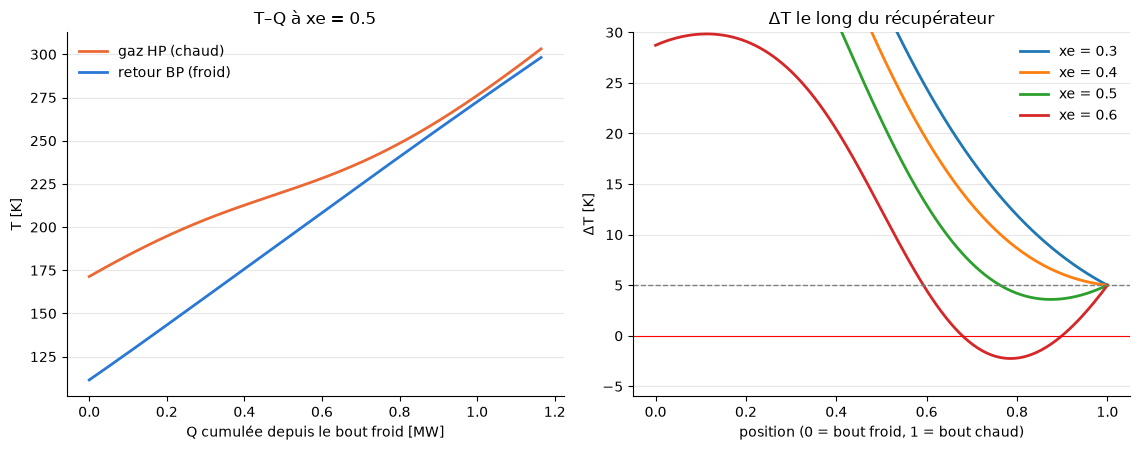

In [18]:
def plot_hx(xe_detail, xe_list):
    HOT, COLD = "#eb6834", "#2a78d6"
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.6))
    p = results[_key(xe_detail)]["prof"]
    a.plot(p["Q"]/1e6, p["T_h"], color=HOT, lw=2, label="gaz HP (chaud)")
    a.plot(p["Q"]/1e6, p["T_c"], color=COLD, lw=2, label="retour BP (froid)")
    a.set(xlabel="Q cumulée depuis le bout froid [MW]", ylabel="T [K]", title=f"T–Q à xe = {xe_detail}")
    a.legend(frameon=False)
    for xe in xe_list:
        p = results[_key(xe)]["prof"]
        b.plot(p["Q"]/p["Q"][-1], p["T_h"] - p["T_c"], lw=2, label=f"xe = {xe}")
    b.axhline(5, color="gray", ls="--", lw=1)
    b.axhline(0, color="red", lw=0.8)
    b.set(xlabel="position (0 = bout froid, 1 = bout chaud)", ylabel="ΔT [K]",
          ylim=(-6, 30), title="ΔT le long du récupérateur")
    b.legend(frameon=False)
    for ax in (a, b):
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout(); plt.show()

plot_hx(0.5, [0.3, 0.4, 0.5, 0.6])

In [20]:
n

NameError: name 'n' is not defined

##